# Topic analysis of state AI legislation

**Question.** Which policy themes recur across state AI bills, how do they differ across states and over time, and do bills in different domains share the same safeguards?

**Approach.** TF-IDF and NMF on NCSL bill summaries (eight topics), with a refined variant that drops summary boilerplate and LDA as a comparison. States, dates, categories, sponsors and outcomes are used only after fitting. Stored bill text is used to verify eight cases.

**Run.** `python -m pip install -r requirements.txt`, then `python src/prepare.py`, then run all cells. Tables, figures and models are written to `outputs/topic_analysis/`. Section 7 summarizes the results.

In [1]:
import sys
import json
import time
import platform
import warnings
import importlib.metadata
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from threadpoolctl import threadpool_limits

In [2]:
# Find the repository root so the notebook runs from any working directory.
root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src/prepare.py").exists() and (p / "notebooks").exists()),
    None,
)
if root is None:
    raise FileNotFoundError("Run inside the siads696-state-of-ai repository")
sys.path.insert(0, str(root))

from src.topic_analysis import (
    TEXT, IDENTIFIERS, LEGAL_STOPWORDS, GEOGRAPHIC_NAMES, sha256,
    load_common, topic_tables, dominant_topics, fit_model, run_experiments, model_review_notes,
    check_topic_identity, distributions, heatmap, leading_word_chart,
    introduction_years, group_share_tables, case_evidence,
    k_selection, recommend_k, k_selection_chart, new_topics_versus,
    distinct_solutions, pair_stability, stability_report, scaling_sensitivity,
    summary_dedup_sensitivity, sponsor_tables, outcome_by_topic, outcome_chart, bill_families,
)

In [3]:
OUT = root / "outputs/topic_analysis"
OUT.mkdir(parents=True, exist_ok=True)

INCLUDE_LDA = True  # LDA is a secondary comparison
BASE_ID = "nmf_baseline_k8_seed42_nndsvda"
CLEAN_ID = "nmf_legal_k8_seed42_nndsvda"

# The case selections and topic labels were reviewed on this exact source file.
EXPECTED_RAW_SHA256 = "188aba4f4e50c6d0acb3532d143b9a81d9cccdf7c0729ba7ded6410399eff232"
assert sha256(root / "data/raw/Final_Database.csv") == EXPECTED_RAW_SHA256, (
    "Source changed: review the fixed case selections and labels before reusing them"
)

In [4]:
pd.set_option("display.max_colwidth", None)
display(HTML(
    "<style>td {vertical-align: top; white-space: normal !important;} "
    "th {text-align: left;} .dataframe {max-width: 100%;}</style>"
))


def show(frame):
    """Display a table without its index, wrapping long text."""
    html = frame.to_html(index=False, escape=True)
    style = '<table style="font-size:12px;table-layout:auto;overflow-wrap:anywhere" '
    display(HTML(html.replace("<table ", style)))

In [5]:
# Reviewed topic labels, and the models they were reviewed on (saved by an earlier run, if any).
labels = json.loads((root / "notebooks/topic_labels.json").read_text(encoding="utf-8"))

reference_path = OUT / "summary_nmf_models.joblib"
reference_models = joblib.load(reference_path) if reference_path.exists() else None

migration = labels["reviewed_migration"]
reviewed_migration = (
    reference_models is not None
    and sha256(reference_path) == migration["reference_model_sha256"]
    and sha256(root / "data/processed/common_intake/common_records.csv") == migration["common_records_sha256"]
)

identity_audit = []  # filled as each model is checked against its reviewed labels

## 1. Data

Input is the shared table from `src/prepare.py`. Only records with an empty `NCSL_Summary_clean` would be excluded; none are. `source_row` is the record's one-based position in the source file, not a bill identifier. NCSL categories are parsed for later comparison (semicolons and commas separate labels; scraping spillover such as `Associated Bills:` is dropped).

In [6]:
# Load the shared table. This checks every retained field, row position and cleaned text against the raw file.
work, audit = load_common(root)
(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")

assert len(work) == audit["included_records"] and work.source_row.is_unique
assert not work[TEXT].str.strip().eq("").any()

# Save how each NCSL category string was parsed.
category_audit = work[["source_row", "NCSL_Category"]].copy()
category_audit["parsed_categories"] = work.categories.map("; ".join)
category_audit.to_csv(OUT / "category_parsing_audit.csv", index=False)

display(Markdown(
    f"**Data:** {audit['raw_records']:,} raw records; "
    f"{len(audit['removed_fulltext_duplicates'])} cleaned-full-text duplicates removed; "
    f"{audit['included_records']:,} summaries modeled across {audit['jurisdictions_including_dc']} jurisdictions. "
    f"{audit['duplicate_clean_summary_extra_records']} records repeat another record's summary; "
    f"{audit['no_category_after_parsing']} have no usable category."
))

**Data:** 2,571 raw records; 4 cleaned-full-text duplicates removed; 2,567 summaries modeled across 51 jurisdictions. 260 records repeat another record's summary; 264 have no usable category.

## 2. Topic model

**Settings.** English stopwords, unigrams and bigrams, `min_df=3`, `max_df=0.85`; NMF with eight topics, NNDSVDa initialization, seed 42. Only `NCSL_Summary_clean` is used.

**Why summaries rather than full text.** Cleaned full texts have a median of about 1,000 words (roughly 400 to 3,200 between the 10th and 90th percentiles), so long bills and statutory boilerplate would dominate the topics. For 37% of records the stored version date differs from the introduction date, so the stored text may be an amended version. NCSL summaries (median 32 words) describe each measure in a consistent format. Full text is used instead to verify the cases in section 4.

**Refined variant.** The baseline produces a topic made of the summary formula "relates to". The refined variant removes four formula words (`relates`, `provides`, `act`, `section`) and is used for all figures; the baseline is kept for comparison. Geography-removal variants are robustness checks only.

In [7]:
# Baseline: TF-IDF on the summaries, then NMF with eight topics.
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.85)
X = vectorizer.fit_transform(work[TEXT])

model = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
started = time.perf_counter()
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=2):
    warnings.simplefilter("always", ConvergenceWarning)
    document_weights = model.fit_transform(X)

baseline = dict(
    vectorizer=vectorizer, X=X, model=model, W=document_weights,
    seconds=time.perf_counter() - started,
    warnings=[str(w.message) for w in caught],
)

# Stop if the topics no longer match the reviewed labels.
identity_audit.extend(
    {"variant": "baseline", **row}
    for row in check_topic_identity(
        baseline, labels["baseline"],
        reference_models["baseline"] if reference_models else None,
        migration["baseline"] if reviewed_migration else None,
    )
)

# Top terms and the five highest-weight summaries of each topic.
baseline_topics, baseline_reps = topic_tables(work, model, document_weights, vectorizer, BASE_ID)
baseline_reps.to_csv(OUT / "baseline_representative_bills.csv", index=False)
assert len(baseline_reps) == 40

topic_summary = baseline_topics.merge(pd.DataFrame(labels["baseline"]), on="topic_id", validate="one_to_one")
topic_summary.to_csv(OUT / "baseline_topic_summary.csv", index=False)

zero_rows = work.loc[X.getnnz(axis=1) == 0, IDENTIFIERS + [TEXT]]  # summaries with no retained terms

In [8]:
# Record why each extra stopword is dropped and how many summaries contain it.
stopword_audit = pd.DataFrame([
    {"term": word, "reason": reason,
     "summaries_containing_word": int(work[TEXT].str.contains(rf"(?i)\b{word}\b", regex=True).sum())}
    for word, reason in LEGAL_STOPWORDS.items()
])
stopword_audit.to_csv(OUT / "stopword_decisions.csv", index=False)
(OUT / "geography_sensitivity_lexicon.json").write_text(json.dumps(GEOGRAPHIC_NAMES, indent=2), encoding="utf-8")

# Fit the refined variant, the robustness variants and LDA.
bundles, comparison, all_topics, all_reps = run_experiments(work, baseline, OUT, include_lda=INCLUDE_LDA)
comparison = comparison.merge(model_review_notes(comparison), on="run_id", validate="one_to_one")
comparison.to_csv(OUT / "model_comparison.csv", index=False)

clean = bundles[CLEAN_ID]
identity_audit.extend(
    {"variant": "refined", **row}
    for row in check_topic_identity(
        clean, labels["legal"],
        reference_models["refined"] if reference_models else None,
        migration["refined"] if reviewed_migration else None,
    )
)

clean_topics = (all_topics.loc[all_topics.run_id.eq(CLEAN_ID)]
                .merge(pd.DataFrame(labels["legal"]), on="topic_id", validate="one_to_one"))
clean_topics.to_csv(OUT / "refined_topic_summary.csv", index=False)

clean_reps = all_reps.loc[all_reps.run_id.eq(CLEAN_ID)].copy()
clean_reps.to_csv(OUT / "refined_representative_bills.csv", index=False)

show(clean_topics[["topic_id", "name", "dominant_records", "keywords"]])

topic_id,name,dominant_records,keywords
0,Generic artificial-intelligence wording (weak),319,"artificial intelligence, intelligence, artificial, use artificial, use, intelligence systems, creates, establishes, systems, companion, intelligence state, chatbots"
1,AI and generative-AI wording (weak),352,"ai, use ai, use, generative, generative ai, ai systems, requires, systems, disclosure, establishes, content, generated"
2,Synthetic media in political communications,213,"media, synthetic, synthetic media, election, deceptive, political, use synthetic, communications, candidate, social media, social, audio"
3,"State administration, education and study bodies (broad)",515,"state, task, task force, force, education, department, requires, technology, establishes, school, public, board"
4,Automated decisions across application domains,166,"decision, automated, employment, automated decision, use automated, systems, making, tools, employment decision, use, decision making, decision systems"
5,Sexual exploitation and intimate imagery,412,"sexual, child, person, image, images, material, intimate, minor, offense, abuse, certain, criminal"
6,Health services and coverage,232,"health, care, health care, insurance, services, mental, mental health, health insurance, certain, patient, utilization, provider"
7,Algorithmic pricing and consumer restrictions,357,"prohibits, algorithmic, consumer, pricing, residential, price, certain, prohibits use, data, use, rental, rent"


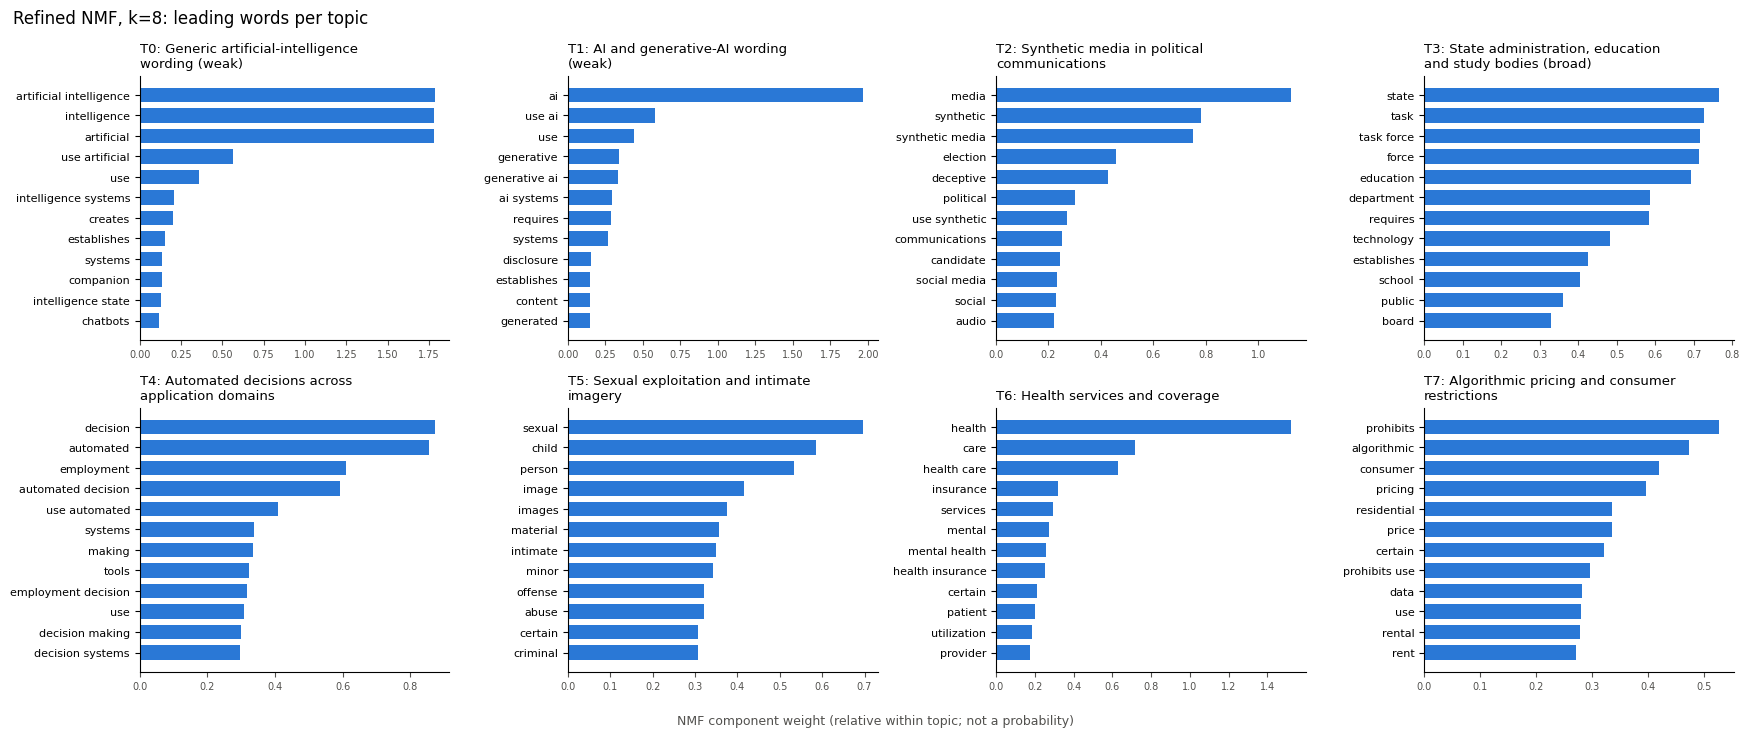

In [9]:
# Leading words per topic: the same 12 terms used in the topic review.
for prefix, bundle, names in [("baseline", baseline, topic_summary), ("refined", clean, clean_topics)]:
    fig = leading_word_chart(
        bundle["model"], bundle["vectorizer"], names.sort_values("topic_id").name.tolist(),
        f"{prefix.title()} NMF, k=8: leading words per topic",
        OUT / f"{prefix}_leading_words.png",
    )
    if prefix == "refined":
        display(fig)
    plt.close(fig)

**Topic labels.** Names were assigned after reading each topic's top terms and its five highest-weight summaries (`refined_representative_bills.csv`). Two topics capture generic AI wording rather than a policy area. One summary (Illinois HR 142, a memorial) has no terms left after filtering; it stays in the data as unassigned.

## 3. Where the topics appear

Figures show the refined model; baseline versions are saved alongside. Each record's topic weights are normalized to shares, and shares are averaged within a group with the record count shown. Shares describe the captured records, not how much a state values a policy or which laws are in force. Cohorts use the introduction year (as in notebook 02); 2026 is a partial year and cohorts with fewer than five records are left out of the figure.

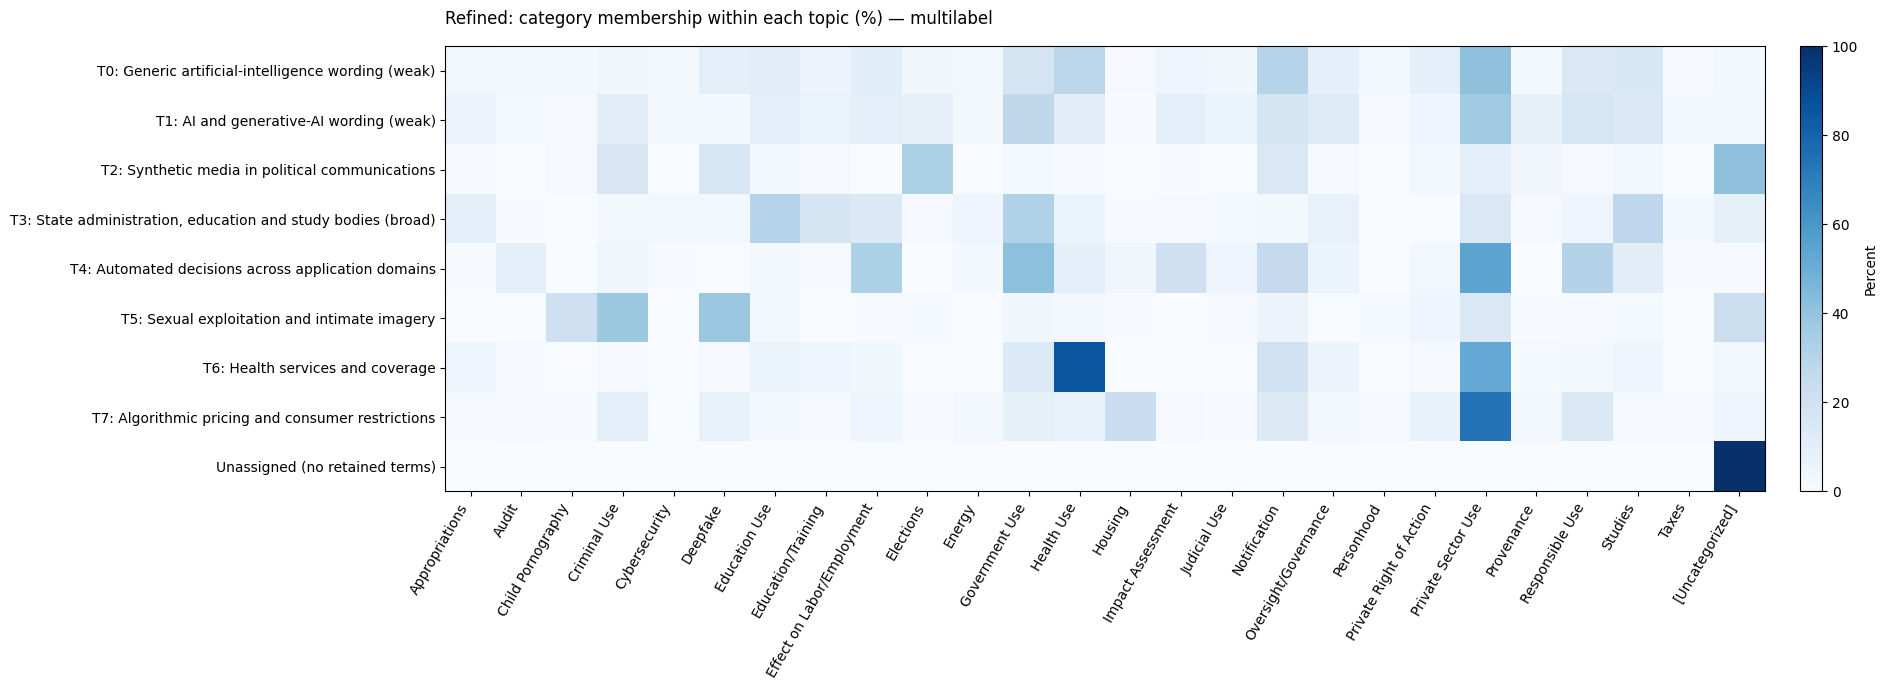

In [10]:
distribution_tables = {}

for prefix, bundle, names in [("baseline", baseline, topic_summary), ("refined", clean, clean_topics)]:
    distribution_tables[prefix] = distributions(work, bundle["W"], OUT, prefix)
    category_shares = distribution_tables[prefix][3]

    row_names = {r.topic_id: f"T{r.topic_id}: {r.name}" for r in names.itertuples()}
    row_names[-1] = "Unassigned (no retained terms)"

    fig = heatmap(
        category_shares.rename(index=row_names),
        f"{prefix.title()}: category membership within each topic (%) — multilabel",
        OUT / f"{prefix}_topic_category_heatmap.png", percent=True, size=(19, 7),
    )
    if prefix == "refined":
        display(fig)
    plt.close(fig)

In [11]:
topic_captions = {
    "baseline": [r["name"] for r in labels["baseline"]],
    "refined": [r["name"] for r in labels["legal"]],
}
records_per_state = work.groupby("Jurisdiction").size()

# Dominant-topic counts and shares by state. Saved only; the mean-share figure below is the one shown.
for prefix in ["baseline", "refined"]:
    counts, shares, _, _ = distribution_tables[prefix]
    row_names = {s: f"{s} (n={records_per_state[s]})" for s in counts.index}
    col_names = {t: f"T{t}: {topic_captions[prefix][t]}" if t >= 0 else "Unassigned" for t in counts.columns}

    for data, suffix, percent, title in [
        (counts, "counts", False, "Dominant-topic record counts"),
        (shares, "proportions", True, "Dominant-topic share within jurisdiction (%)"),
    ]:
        fig = heatmap(
            data.rename(index=row_names, columns=col_names),
            f"{prefix.title()}: {title}",
            OUT / f"{prefix}_state_topic_{suffix}.png", percent=percent, size=(12, 17),
        )
        plt.close(fig)

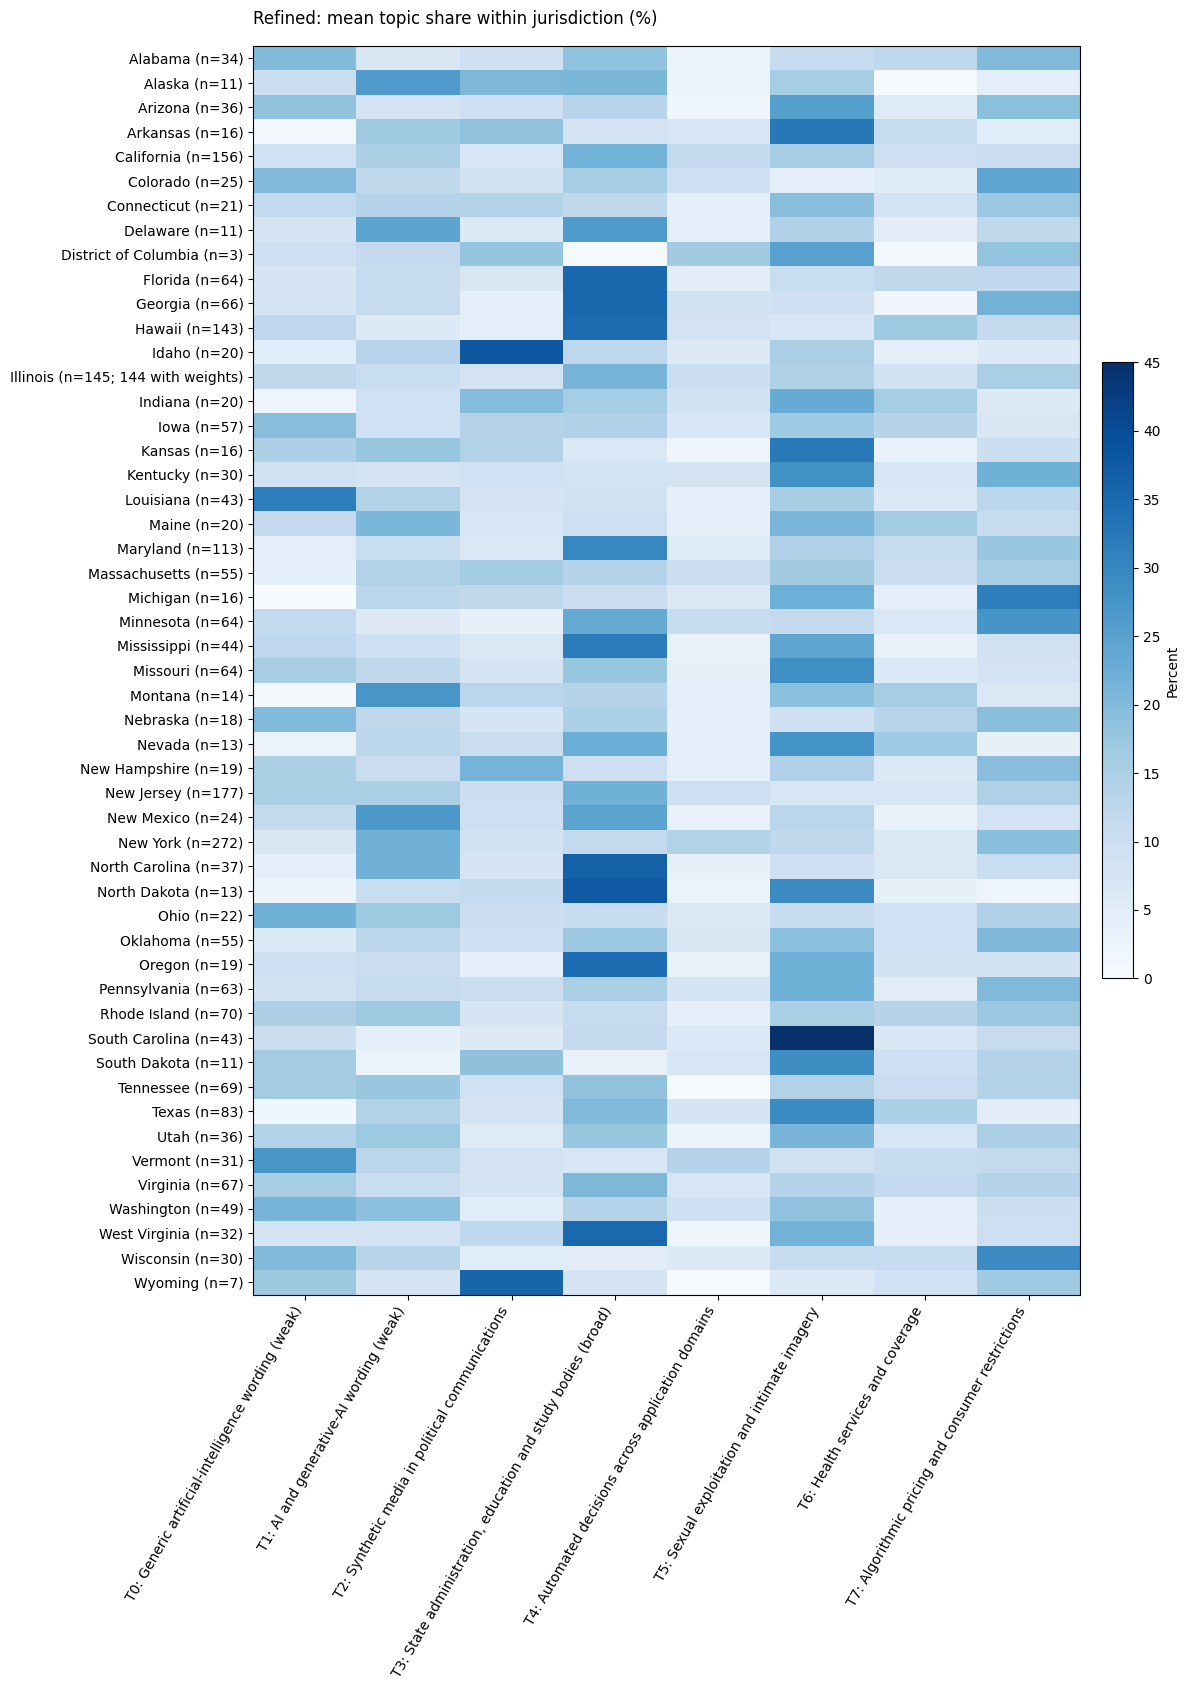

In [12]:
group_tables = {
    prefix: group_share_tables(work, bundle["W"], OUT, prefix)
    for prefix, bundle in [("baseline", baseline), ("refined", clean)]
}


def count_label(name, counts):
    """Label a row with its record count, and with the number of weighted records if fewer."""
    n, assigned = counts.loc[name, "records"], counts.loc[name, "assigned_records"]
    return f"{name} (n={n})" if n == assigned else f"{name} (n={n}; {assigned} with weights)"


def share_ceiling(means):
    """Top of the color scale: the largest share, rounded up to the next 5%."""
    return float(np.ceil(means.to_numpy().max() * 100 / 5) * 5)


for prefix in ["baseline", "refined"]:
    means, counts = group_tables[prefix]["state"]
    col_names = {t: f"T{t}: {topic_captions[prefix][t]}" for t in means.columns}

    fig = heatmap(
        means.rename(index=lambda s: count_label(s, counts), columns=col_names),
        f"{prefix.title()}: mean topic share within jurisdiction (%)",
        OUT / f"{prefix}_state_mean_topic_shares.png",
        percent=True, size=(12, 17), vmax=share_ceiling(means),
    )
    if prefix == "refined":
        display(fig)
    plt.close(fig)

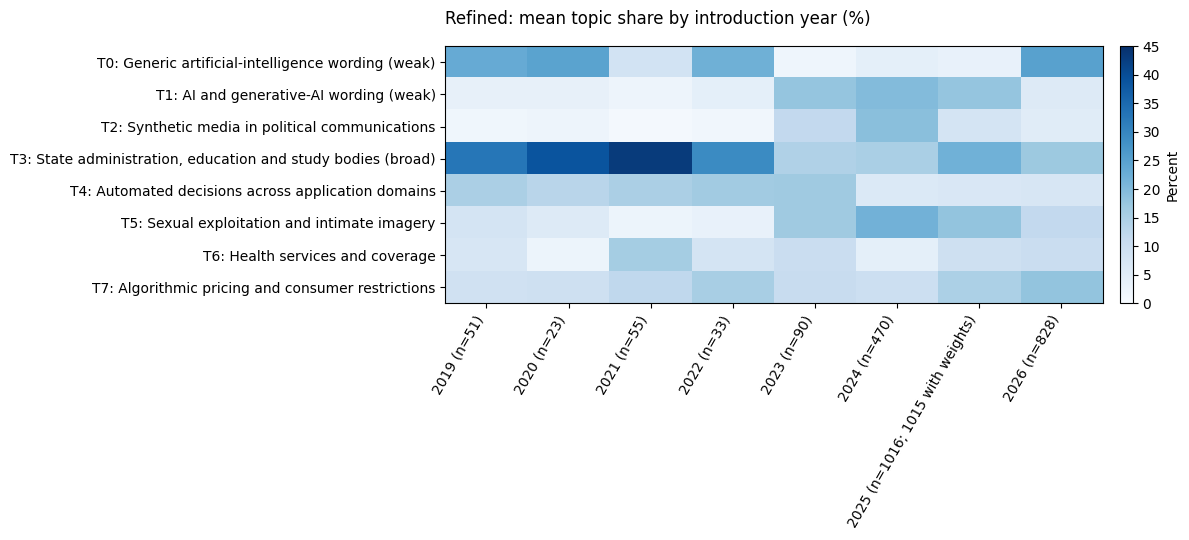

**Cohort coverage:** 2018: 1, 2019: 51, 2020: 23, 2021: 55, 2022: 33, 2023: 90, 2024: 470, 2025: 1,016, 2026: 828 records. The latest introduction date is 2026-04-02, so 2026 is a partial year. Cohorts with fewer than 50 records (2018, 2020, 2022) are shown for completeness; small differences there are not interpretable.

In [13]:
for prefix in ["baseline", "refined"]:
    means, counts = group_tables[prefix]["cohort"]
    means = means.loc[counts.records.ge(5)]
    col_names = {t: f"T{t}: {topic_captions[prefix][t]}" for t in means.columns}

    # Topics as rows keep the long names horizontal; years become short columns.
    fig = heatmap(
        means.T.rename(index=col_names, columns=lambda y: count_label(y, counts)),
        f"{prefix.title()}: mean topic share by introduction year (%)",
        OUT / f"{prefix}_cohort_mean_topic_shares.png",
        percent=True, size=(12, 5.5), vmax=share_ceiling(means),
    )
    if prefix == "refined":
        display(fig)
    plt.close(fig)

cohort_counts = group_tables["refined"]["cohort"][1]
small = cohort_counts.index[cohort_counts.records.lt(50)].tolist()
coverage = ", ".join(f"{year}: {n:,}" for year, n in cohort_counts.records.items())

display(Markdown(
    f"**Cohort coverage:** {coverage} records. "
    f"The latest introduction date is {work.introduction_date_iso.max()}, "
    f"so {cohort_counts.index.max()} is a partial year. "
    f"Cohorts with fewer than 50 records ({', '.join(map(str, small))}) are shown for completeness; "
    "small differences there are not interpretable."
))

## 4. Eight cases: shared provisions across domains

The selection is **purposive and exploratory**: inspect baseline topics 3 and 4, read their top-weight candidates, then retain eight records that contrast domains, jurisdictions and obligations. Select only one Illinois Future of Work measure to avoid treating its many versions as independent corroboration. These eight cases are not a random sample or an estimate of prevalence. Source categories are kept as supplied; application domains below are annotations from the text.

**Relationship A — safeguards around automated decisions.** IN H 1421 and NY A 9601 (employment) and SC S 443 (coverage) prohibit sole reliance on automation and specify human oversight. NY S 6471-A (housing) and NY S 8115-B (lending) share notice and assessment requirements with the employment case, but do not establish an identical human-appeal right. The lending appeal specifically concerns incorrect personal information. SC's operative clause says **health care professional**, whereas its title/summary says **licensed physician**; the report uses the operative language and flags the unexamined cross-reference.

**Relationship B — study bodies with reporting duties.** IL S 2481 (workforce), UT H 168 (education), and CO S 240 (electronic discovery) create study/reporting structures across domains. Colorado's AI transcription provision is only one part of a wider electronic-discovery measure, so this supports a shared institutional approach, not a common substantive AI safeguard. Source categories already include `Studies` for some records: the result reveals a useful relation, not a wholly absent concept.

**Same category, different approach.** IL S 2481 and IN H 1421 both carry `Effect on Labor/Employment`, but the first establishes a study body and the second imposes employer-facing duties. Their topic separation complements the across-domain similarities.

Every excerpt in `case_analysis.csv` comes from the stored **original `Bill_Text`**, with a text checksum, section locator and original character offsets (zero-based, end exclusive). Matching is checked during execution. The corpus can contain amended/extracted text with lost markup; these are version-specific findings, not a statement that a proposal was enacted or remains current.

In [14]:
case_spec = json.loads((root / "notebooks/topic_case_review.json").read_text(encoding="utf-8"))
cases = case_evidence(work, case_spec["cases"], bundles, OUT)

# Each case's dominant topic, and its rank among all records by that topic's weight.
position = {source_row: i for i, source_row in enumerate(work.source_row)}

for name, bundle in [("baseline", baseline), ("refined", clean)]:
    topics = dominant_topics(bundle["W"])
    case_topics, case_ranks = [], []

    for source_row in cases.source_row:
        i = position[source_row]
        topic = int(topics[i])
        order = np.argsort(-bundle["W"][:, topic], kind="stable")
        case_topics.append(topic)
        case_ranks.append(int(np.flatnonzero(order == i)[0] + 1))

    cases[f"{name}_topic"] = case_topics
    cases[f"{name}_rank_within_topic"] = case_ranks

cases.to_csv(OUT / "case_analysis.csv", index=False)

show(cases[[
    *IDENTIFIERS, "NCSL_Category", "application_domain",
    "baseline_topic", "baseline_rank_within_topic", "refined_topic",
    "concrete_requirements", "differences_and_limits",
]])

source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,application_domain,baseline_topic,baseline_rank_within_topic,refined_topic,concrete_requirements,differences_and_limits
1856,Indiana,H 1421,2026,"Effect on Labor/Employment, Notification, Private Sector Use, Private Right of Action, Responsible Use",Employment,4,3,4,"No exclusive automated reliance; predeployment validation, annual independent bias testing with public results, experienced human corroboration, disclosure, and human dispute/appeal channels.",More extensive safeguards than SC S 443; a different experienced human hears an appeal. The employer definition excludes labor organizations except in their employer role. This is proposed text in the stored introduced version.
2258,New York,A 9601,2026,"Effect on Labor/Employment, Notification, Private Sector Use",Employment,4,7,4,"Meaningful human evaluation before final/adverse decisions, override authority, notice of automated use and data types, and human review on an unsuccessful applicant's request.",This short hiring-focused bill does not establish the same annual independent testing package as IN H 1421; the cited sections should not be generalized to every employment decision.
709,South Carolina,S 443,2025,Health Use; Private Sector Use,Health coverage,4,45,4,No coverage action based solely on AI/tool results; professional supervision and meaningful review when automated tools inform modification or denial of authorization.,"The title/summary says licensed physician, but operative subsection (C) says health care professional (section 44-30-20). No applicant notice, annual audit or human appeal package is stated in this short stored bill. The referenced definition was not independently examined."
575,New York,S 6471,2025,Housing; Private Sector Use; Impact Assessment,Housing applicant screening,4,42,4,"Annual disparate-impact analysis by an independent auditor; public analysis summary; notice about use, characteristics and data; denial reasons; at least 24-hour prior notice enabling an alternative selection process or accommodation request.","An alternative process/accommodation request is not an explicit universal right to a human override. Tool scope excludes non-discretionary software. Stored text is S 6471-A, while the source identifier omits the amendment suffix."
589,New York,S 8115,2025,Private Sector Use,Lending,4,8,4,"At least annual impact assessments signed by responsible human reviewers, assessments before material changes, public final reports, notice, and a 30-day correction/appeal route for denials based on incorrect personal information.",The appeal is conditional on incorrect personal information. Human review of an impact assessment does not establish review of every loan decision. The housing bill specifies an independent auditor; this text specifies signatures of responsible reviewers. Stored version is S 8115-B; federal banks and other listed institutions are excluded.
1456,Illinois,S 2481,2021,Effect on Labor/Employment,Workforce and employment,3,1,3,"Assess emerging technologies and workforce effects, propose training and other policies, and submit a final report to the Governor and General Assembly.",Dissolves on filing its final report; broader future-of-work remit than AI alone. IN H 1421 shares the Effect on Labor/Employment label but imposes direct employer obligations rather than establishing a study body. Repeated Illinois companion/version summaries are not independent evidence.
797,Utah,H 168,2025,Education Use; Studies,Education,3,13,3,"Study and recommend education AI policies, privacy safeguards and implementation guidelines; coordinate with the AI policy office; meet at least quarterly and report annually to legislative education committees.","Annual reporting contrasts with Illinois's final report and dissolution. The text addresses student privacy and educational agency without imposing a universal individual decision appeal. Stored plain text contains amendment remnants, so

## 5. Model choice and robustness

**NMF versus LDA.** Topics are compared on in-sample coherence (NPMI of the top 12 terms), term diversity and overlap between topics; NMF error and LDA likelihood are not compared with each other. `model_comparison.csv` keeps every run.

In [15]:
# Main runs only (seed 42); model_comparison.csv keeps every run.
primary = comparison.loc[comparison.seed.eq(42) & comparison.initialization.isin(["nndsvda", "batch"])]
show(primary[[
    "method", "variant", "topics", "document_npmi_top12",
    "top12_term_diversity", "mean_top12_jaccard", "ari_vs_baseline",
]].round(3))

warned = comparison.loc[comparison.convergence_warnings.ne(""), ["run_id", "convergence_warnings"]]
if len(warned):
    show(warned)

method,variant,topics,document_npmi_top12,top12_term_diversity,mean_top12_jaccard,ari_vs_baseline
NMF,baseline,5,0.181,0.867,0.040,0.578
NMF,baseline,6,0.161,0.861,0.036,0.715
NMF,baseline,8,0.160,0.885,0.024,1.000
NMF,baseline,10,0.189,0.900,0.016,0.633
NMF,baseline,12,0.191,0.896,0.013,0.514
NMF,legal,8,0.211,0.896,0.026,0.454
NMF,geography,8,0.160,0.875,0.027,0.938
NMF,legal_geography,8,0.237,0.906,0.022,0.580
LDA,baseline,5,0.066,0.583,0.206,0.181
LDA,baseline,8,0.090,0.594,0.143,0.197


**Topic count.** Each k from 5 to 12 is fit five times (NNDSVDa plus four random starts). The NNDSVDa seeds alone are not independent: at k=8 they reach practically the same solution. Rule: among counts within 0.01 of the best mean NPMI, pick the one whose topics match best across starts. The rule was set after the k=8 review, so it is a check rather than a pre-registered choice; section 7 records the decision.

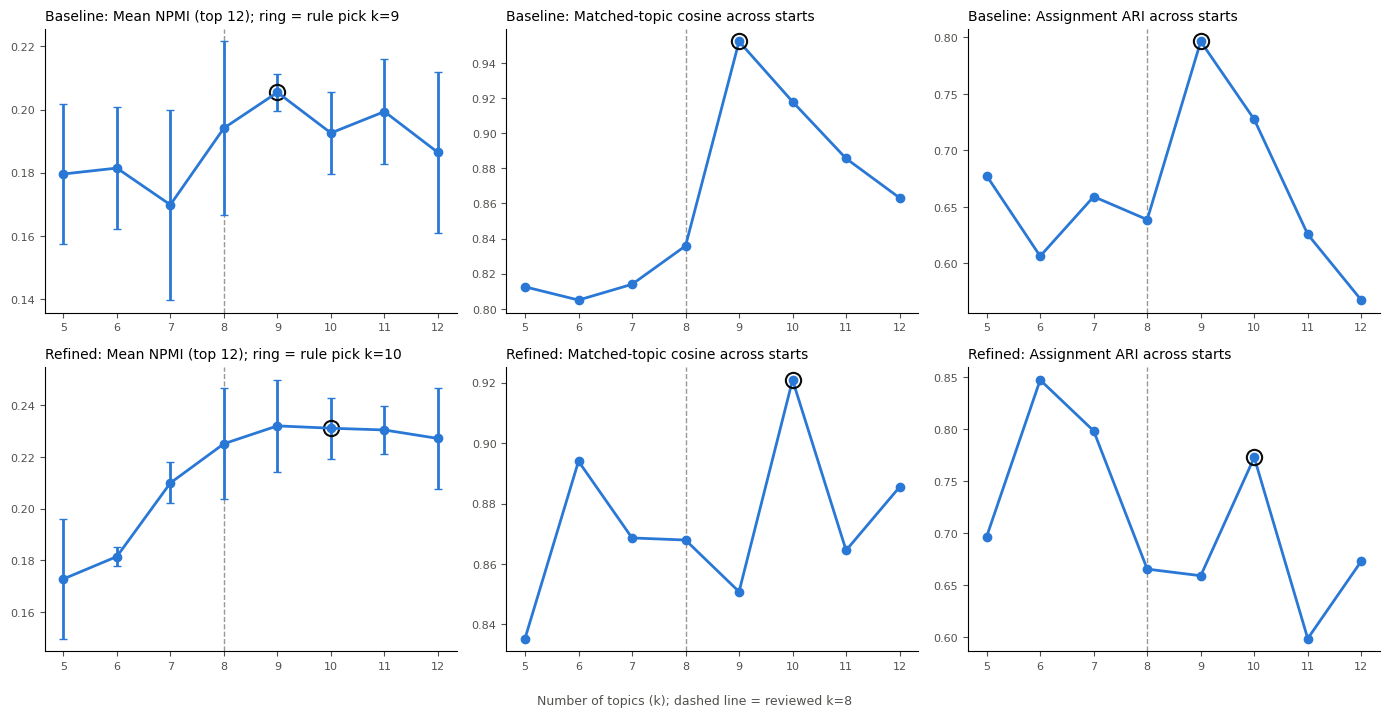

**Rule result:** baseline favors k=9, not the reviewed k=8; refined favors k=10, not the reviewed k=8.

variant,NPMI tolerance 0.005,NPMI tolerance 0.01,NPMI tolerance 0.015,NPMI tolerance 0.02,NPMI tolerance 0.03
Baseline,9,9,9,9,9
Refined,10,10,10,10,10


In [16]:
k_tables = {
    "Baseline": k_selection(work, OUT, "baseline"),
    "Refined": k_selection(work, OUT, "legal", prefix="refined"),
}
fig = k_selection_chart(k_tables, 8, OUT / "k_selection.png")
display(fig)
plt.close(fig)

k_picks = {label: recommend_k(table) for label, table in k_tables.items()}
rule_text = [
    f"{label.lower()} favors k={k}, " + ("matching" if k == 8 else "not") + " the reviewed k=8"
    for label, k in k_picks.items()
]
display(Markdown("**Rule result:** " + "; ".join(rule_text) + "."))

# Does the pick change with the NPMI tolerance?
tolerances = [0.005, 0.01, 0.015, 0.02, 0.03]
show(pd.DataFrame([
    {"variant": label, **{f"NPMI tolerance {t}": recommend_k(table, t) for t in tolerances}}
    for label, table in k_tables.items()
]))

In [17]:
# Fit the rule's pick and list its topics that have no close match among the reviewed k=8 topics.
k_alternatives = {}

for label, bundle in [("Baseline", baseline), ("Refined", clean)]:
    k = k_picks[label]
    if k == 8:
        continue

    model_k, W_k, _, _ = fit_model(bundle["X"], "NMF", k, 42, "nndsvda")
    extra = new_topics_versus(bundle, dict(model=model_k, W=W_k, vectorizer=bundle["vectorizer"]))
    k_alternatives[label] = dict(model=model_k, extra=extra)

    display(Markdown(f"**{label}, k={k} (NNDSVDa): topics without a close reviewed k=8 match "
                     "(best component cosine < 0.8)**"))
    show(extra.round(2))

**Baseline, k=9 (NNDSVDa): topics without a close reviewed k=8 match (best component cosine < 0.8)**

topic_id,dominant_records,closest_reviewed_topic,closest_cosine,top_terms
8,550,2,0.49,"provides, act, consumer, prohibits, algorithmic, pricing, certain, protection, price, data"


**Refined, k=10 (NNDSVDa): topics without a close reviewed k=8 match (best component cosine < 0.8)**

topic_id,dominant_records,closest_reviewed_topic,closest_cosine,top_terms
3,61,3,0.58,"task, task force, force, establishes, intelligence task, creates, establishes task, recommendations, force shall, membership"
9,19,3,0.01,"commends, recognizes, dr, challenge, years, congratulates, continued success, wishes, wishes continued, dedicated"


**Stability of the case relationships.** For each selected pair of bills, check whether both share a dominant topic in every distinct NMF solution (runs that reach the same solution, ARI >= 0.99, are counted once). One pair is a contrast that should stay apart.

In [18]:
# Runs that reach the same solution are counted once.
distinct_bundles, collapsed_runs = distinct_solutions(bundles)
collapsed_runs.to_csv(OUT / "collapsed_duplicate_runs.csv", index=False)

pair_results = pair_stability(work, distinct_bundles, case_spec["pairs"], OUT)
pair_results["method"] = pair_results.run_id.str.split("_").str[0].str.upper()

# A "similar" pair should share a dominant topic; the contrast pair should not.
pair_results["relationship_preserved"] = np.where(
    pair_results.expected_relation.eq("similar"),
    pair_results.same_dominant_topic,
    ~pair_results.same_dominant_topic,
)

stability_summary = (
    pair_results
    .groupby(["method", "a", "b", "relationship", "expected_relation"], sort=False)
    .agg(runs=("run_id", "size"),
         preserved_runs=("relationship_preserved", "sum"),
         minimum_weight_cosine=("topic_weight_cosine", "min"))
    .reset_index()
)
stability_summary.to_csv(OUT / "case_stability_summary.csv", index=False)

show(stability_summary[["method", "relationship", "runs", "preserved_runs"]])
display(Markdown(stability_report(pair_results)))

method,relationship,runs,preserved_runs
NMF,Employment/health: no sole automation and human oversight,12,12
NMF,Hiring/health: meaningful human review,12,12
NMF,"Employment/housing: testing and disclosure, different remedies",12,12
NMF,"Housing/lending: assessment and notice, different review scope",12,12
NMF,Workforce/education: study body and reporting,12,12
NMF,Workforce/justice: study body and reporting,12,12
NMF,Education/justice: study body and reporting,12,12
NMF,Same labor category: study institution versus direct safeguards,12,12
LDA,Employment/health: no sole automation and human oversight,4,3
LDA,Hiring/health: meaningful human review,4,4


**NMF: 12 distinct solutions, 7 selected similarity pairs.** Shared dominant topic in 84/84 pair-setting checks. The contrasting pairs remain separated in 12/12 checks.

**LDA: 4 distinct solutions, 7 selected similarity pairs.** Shared dominant topic in 24/28 pair-setting checks. The contrasting pairs remain separated in 4/4 checks.

These are sensitivity results for cases selected after the initial fit, not validation of every topic boundary or independent confirmation. Topic-weight scaling, corpus coverage and limited LDA training remain limitations; provisions establish the specific commonalities.

**Weight scaling and repeated summaries.** NMF weights can be rescaled without changing the fit, which can move dominant-topic counts; the first table shows how many records change under a unit-mass convention. The second refits on unique summaries only and compares assignments.

In [19]:
scaling_summary, scaling_pairs = scaling_sensitivity(work, distinct_bundles, case_spec["pairs"], OUT)
show(scaling_summary[["run_id", "changed_fraction", "maximum_state_topic_shift_percentage_points"]].round(3))

run_id,changed_fraction,maximum_state_topic_shift_percentage_points
nmf_baseline_k5_seed42_nndsvda,0.131,28.571
nmf_baseline_k6_seed42_nndsvda,0.213,46.875
nmf_baseline_k8_seed42_nndsvda,0.219,42.857
nmf_baseline_k10_seed42_nndsvda,0.213,29.851
nmf_baseline_k12_seed42_nndsvda,0.230,36.364
nmf_baseline_k6_seed7_nndsvda,0.145,28.571
nmf_baseline_k10_seed21_nndsvda,0.218,29.688
nmf_baseline_k8_seed7_random,0.121,28.571
nmf_baseline_k8_seed21_random,0.150,33.333
nmf_legal_k8_seed42_nndsvda,0.119,23.077


In [20]:
summary_sensitivity = summary_dedup_sensitivity(work, baseline, OUT)
show(pd.DataFrame([summary_sensitivity])[[
    "original_records", "unique_summaries", "aligned_assignment_changes", "adjusted_rand_index",
]].round(3))

# Saved for the report only: sponsor tables and the label-alignment audit.
for prefix, bundle in [("baseline", baseline), ("refined", clean)]:
    sponsor_tables(work, bundle, OUT, prefix)
pd.DataFrame(identity_audit).to_csv(OUT / "previous_run_topic_alignment.csv", index=False)

original_records,unique_summaries,aligned_assignment_changes,adjusted_rand_index
2567,2307,380,0.692


## 6. Exploratory checks (post hoc)

Two checks were added after the main review. They are **hypotheses, not confirmatory results**: topics, outcome definitions and the similarity threshold were all examined on the same data.

### Recorded outcomes by topic

Only resolved bills are used. Enacted and Adopted count as passed; Failed and Vetoed as failed; pending records are left out. Resolutions and memorials (bill prefixes such as HR, SCR and HJM) are removed, as the proposal specifies. Each topic is compared with all other topics within introduction-year × party-control strata (Mantel–Haenszel odds ratio with a CMH test), so year and partisan context are held fixed. With eight topics the Bonferroni threshold is 0.05/8.

Topics come from summaries of each bill, and a summary may be written after the bill has moved. These are associations, not causes.

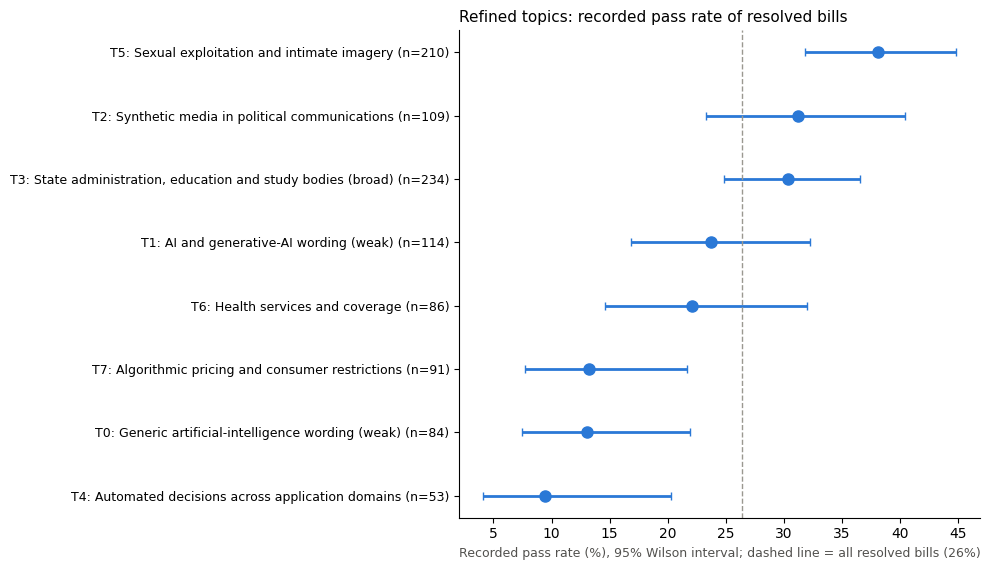

topic_id,name,resolved_bills,pass_rate,pass_rate_2019_2024,pass_rate_2025_2026,stratified_odds_ratio_vs_other_topics,cmh_p
4,Automated decisions across application domains,53,0.094,0.065,0.136,0.243,0.008
0,Generic artificial-intelligence wording (weak),84,0.131,0.143,0.125,0.589,0.194
7,Algorithmic pricing and consumer restrictions,91,0.132,0.150,0.127,0.438,0.011
6,Health services and coverage,86,0.221,0.214,0.224,0.687,0.213
1,AI and generative-AI wording (weak),114,0.237,0.102,0.338,0.695,0.159
3,"State administration, education and study bodies (broad)",234,0.303,0.260,0.338,1.352,0.108
2,Synthetic media in political communications,109,0.312,0.261,0.400,1.385,0.203
5,Sexual exploitation and intimate imagery,210,0.381,0.333,0.407,1.835,0.001


**Result:** 981 resolved bills after excluding 106 resolutions and memorials; overall pass rate 26%. Topic and outcome are associated (chi-square p = 4e-07). Lowest: T4 Automated decisions across application domains, 9% (stratified OR 0.24, p = 0.0078). Highest: T5 Sexual exploitation and intimate imagery, 38% (stratified OR 1.84, p = 0.00062). Below the Bonferroni threshold: T5. The 2019-2024 and 2025-2026 columns show whether the ordering repeats in the later cohort.

In [17]:
outcome_table, outcome_audit = outcome_by_topic(work, clean["W"], topic_captions["refined"], OUT, "refined")
fig = outcome_chart(outcome_table, outcome_audit["overall_pass_rate"],
    "Refined topics: recorded pass rate of resolved bills", OUT / "refined_topic_outcomes.png")
display(fig); plt.close(fig)
show(outcome_table[["topic_id", "name", "resolved_bills", "pass_rate", "pass_rate_2019_2024",
                    "pass_rate_2025_2026", "stratified_odds_ratio_vs_other_topics", "cmh_p"]].round(3))
low, high = outcome_table.iloc[0], outcome_table.iloc[-1]
significant = [f"T{r.topic_id}" for r in outcome_table.itertuples() if r.cmh_p < outcome_audit["bonferroni_alpha"]]
display(Markdown(
    f"**Result:** {outcome_audit['resolved_bills']:,} resolved bills after excluding "
    f"{outcome_audit['resolutions_and_memorials_excluded']} resolutions and memorials; overall pass rate "
    f"{outcome_audit['overall_pass_rate']:.0%}. Topic and outcome are associated "
    f"(chi-square p = {outcome_audit['chi2_p_topic_by_outcome']:.1g}). "
    f"Lowest: T{low.topic_id} {low['name']}, {low.pass_rate:.0%} (stratified OR "
    f"{low.stratified_odds_ratio_vs_other_topics:.2f}, p = {low.cmh_p:.2g}). "
    f"Highest: T{high.topic_id} {high['name']}, {high.pass_rate:.0%} (stratified OR "
    f"{high.stratified_odds_ratio_vs_other_topics:.2f}, p = {high.cmh_p:.2g}). "
    f"Below the Bonferroni threshold: {', '.join(significant) or 'none'}. "
    "The 2019-2024 and 2025-2026 columns show whether the ordering repeats in the later cohort."))

### Multi-state bill families

Bills from different jurisdictions whose cleaned full texts reach TF-IDF cosine ≥ 0.5 (word 1-3-grams) are linked, and linked groups spanning four or more jurisdictions are listed. Such groups suggest a shared drafting source, such as model legislation, but similarity alone does not establish a common origin. Linking is single-linkage and the result depends on the threshold (first table), so the families are leads for reading, not a census. This also marks bill families for the family-aware validation the proposal requires.

In [18]:
family_table, family_sensitivity, family_audit = bill_families(work, clean["W"], topic_captions["refined"], OUT)
show(family_sensitivity)
show(family_table[["jurisdictions", "bills", "first_introduced", "last_introduced", "dominant_topic",
                   "example_title", "resolved_bills", "passed"]])
display(Markdown(
    f"**Result:** {family_audit['families']} families with {family_audit['bills_in_families']} bills at threshold "
    f"{family_audit['threshold']}. Among resolved bills (resolutions excluded), "
    f"{family_audit['family_pass_rate']:.0%} of family members passed (n={family_audit['family_resolved_bills']}) "
    f"versus {family_audit['other_pass_rate']:.0%} of other bills (n={family_audit['other_resolved_bills']}). "
    "The family sample is small and threshold-dependent; treat the gap as a lead, not an estimate."))

threshold,cross_state_pairs,families,bills_in_families
0.5,339,11,86
0.6,146,3,21
0.7,68,1,6


jurisdictions,bills,first_introduced,last_introduced,dominant_topic,example_title,resolved_bills,passed
9,16,2024-01-09,2026-01-07,T2: Synthetic media in political communications,Electioneering Communications,10,0
8,11,2025-01-27,2026-03-06,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,1,0
6,8,2025-10-16,2026-03-31,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,2,1
5,10,2024-01-10,2026-04-02,T7: Algorithmic pricing and consumer restrictions,Residential Landlord and Tenant Act,4,0
5,7,2023-01-30,2025-02-07,T4: Automated decisions across application domains,Automated Decision Tools,3,0
5,7,2024-01-24,2025-02-03,T5: Sexual exploitation and intimate imagery,ELVIS Act of 2025,4,1
5,6,2025-01-29,2026-02-02,"T3: State administration, education and study bodies (broad)",Clean Air Preservation Act,1,0
5,6,2025-12-12,2026-02-11,T7: Algorithmic pricing and consumer restrictions,Consumer Protection,0,0
4,6,2021-03-02,2025-02-04,T7: Algorithmic pricing and consumer restrictions,Business Regulation Regarding Insurance Discrimination,3,1
4,5,2024-12-02,2026-03-09,T4: Automated decisions across application domains,Employment: Automated Decision Systems,0,0


**Result:** 11 families with 86 bills at threshold 0.5. Among resolved bills (resolutions excluded), 11% of family members passed (n=28) versus 27% of other bills (n=953). The family sample is small and threshold-dependent; treat the gap as a lead, not an estimate.

## 7. Key results

Computed from the outputs above (refined NMF, eight topics). Report figures: `refined_leading_words.png`, `refined_state_mean_topic_shares.png`, `refined_cohort_mean_topic_shares.png`, `k_selection.png`, `refined_topic_outcomes.png`.

In [19]:
from sklearn.metrics.pairwise import cosine_similarity
names = topic_captions["refined"]
label = lambda t: f"T{t} {names[t]}"
policy = [t for t in range(len(names)) if "(weak)" not in names[t]]

# Cohorts: record-weighted mean shares for three periods.
cohort_means, cohort_counts = group_tables["refined"]["cohort"]
def pooled(years):
    keep = [y for y in years if y in cohort_means.index]
    weights = cohort_counts.loc[keep, "records"]
    return cohort_means.loc[keep].mul(weights, axis=0).sum() / weights.sum()
periods = {"2019-2023": pooled(range(2019, 2024)), "2024": pooled([2024]), "2025-2026": pooled([2025, 2026])}
peaks = {p: [t for t in policy if max(periods, key=lambda q: periods[q][t]) == p] for p in periods}
cohort_text = "; ".join(f"{p}: " + ", ".join(f"{label(t)} ({periods[p][t]:.0%})" for t in ts)
                        for p, ts in peaks.items() if ts)

# States: largest mean shares among jurisdictions with at least 40 records.
state_means, state_counts = group_tables["refined"]["state"]
large = state_means.loc[state_counts.records.ge(40)]
state_text = "; ".join(f"{label(t)}: {large[t].idxmax()} ({large[t].max():.0%})" for t in policy)

# Topic count: what the rule's alternative adds to the reviewed topics.
alt = k_alternatives.get("Refined")
if alt is None:
    k_text = "The multi-start rule also favors k=8 for the refined model."
else:
    recovered = int((cosine_similarity(clean["model"].components_, alt["model"].components_).max(axis=1) >= .8).sum())
    added = "; ".join(f"{r.top_terms.split(', ')[0]}/{r.top_terms.split(', ')[1]} ({r.dominant_records} records)"
                      for r in alt["extra"].itertuples())
    k_text = (f"The multi-start rule favors k={k_picks['Refined']} for the refined model; that model reproduces "
              f"{recovered} of the 8 reviewed topics (component cosine >= 0.8) and adds small topics: {added}. "
              "k=8 is kept as the final model because its labels and case evidence were reviewed"
              + (" and every reviewed theme survives at the larger count." if recovered == 8 else "."))

# NMF versus LDA at the same k.
nmf8 = comparison.set_index("run_id").loc[BASE_ID]
lda = comparison.loc[comparison.method.eq("LDA")]
lda8 = lda.set_index("topics").loc[8]

# Case relationships across distinct NMF solutions.
nmf_pairs = stability_summary.loc[stability_summary.method.eq("NMF")]
low, high = outcome_table.iloc[0], outcome_table.iloc[-1]

display(Markdown("\n".join([
    f"1. **Themes.** Eight topics: " + "; ".join(label(t) for t in range(len(names))) + ". "
    "Two are generic AI-wording topics rather than policy areas.",
    f"2. **States.** Highest mean share for each policy topic among states with 40+ records: {state_text}. "
    "Shares describe the captured records, not state priorities.",
    f"3. **Cohorts.** Peak period for each policy topic, with its mean share: {cohort_text}. 2024 was a U.S. election year; "
    f"2026 runs only to {work.introduction_date_iso.max()}.",
    f"4. **Topic count.** {k_text}",
    f"5. **NMF versus LDA.** With the same vocabulary and k=8, baseline NMF topics are more distinct and coherent than LDA topics: top-12 term "
    f"diversity {nmf8.top12_term_diversity:.2f} vs {lda8.top12_term_diversity:.2f}, mean top-12 overlap "
    f"{nmf8.mean_top12_jaccard:.2f} vs {lda8.mean_top12_jaccard:.2f}, NPMI {nmf8.document_npmi_top12:.2f} vs "
    f"{lda8.document_npmi_top12:.2f}. LDA diversity stays at or below {lda.top12_term_diversity.max():.2f} for "
    "every k tested, so NMF is the main method.",
    f"6. **Shared provisions.** The {len(nmf_pairs)} selected case relationships hold in "
    f"{int(nmf_pairs.preserved_runs.sum())} of {int(nmf_pairs.runs.sum())} checks across "
    f"{int(nmf_pairs.runs.max())} distinct NMF solutions (section 5).",
    f"7. **Outcomes (post hoc).** Resolved bills pass at {outcome_audit['overall_pass_rate']:.0%} overall; "
    f"{label(high.topic_id)} is highest at {high.pass_rate:.0%} and {label(low.topic_id)} lowest at "
    f"{low.pass_rate:.0%}. Both differences hold with introduction year and party control held fixed "
    f"(stratified odds ratios {high.stratified_odds_ratio_vs_other_topics:.2f} and "
    f"{low.stratified_odds_ratio_vs_other_topics:.2f}; section 6).",
])))

1. **Themes.** Eight topics: T0 Generic artificial-intelligence wording (weak); T1 AI and generative-AI wording (weak); T2 Synthetic media in political communications; T3 State administration, education and study bodies (broad); T4 Automated decisions across application domains; T5 Sexual exploitation and intimate imagery; T6 Health services and coverage; T7 Algorithmic pricing and consumer restrictions. Two are generic AI-wording topics rather than policy areas.
2. **States.** Highest mean share for each policy topic among states with 40+ records: T2 Synthetic media in political communications: Massachusetts (16%); T3 State administration, education and study bodies (broad): Florida (35%); T4 Automated decisions across application domains: New York (14%); T5 Sexual exploitation and intimate imagery: South Carolina (45%); T6 Health services and coverage: Hawaii (17%); T7 Algorithmic pricing and consumer restrictions: Minnesota (27%). Shares describe the captured records, not state priorities.
3. **Cohorts.** Peak period for each policy topic, with its mean share: 2019-2023: T3 State administration, education and study bodies (broad) (28%), T4 Automated decisions across application domains (16%); 2024: T2 Synthetic media in political communications (19%), T5 Sexual exploitation and intimate imagery (22%); 2025-2026: T6 Health services and coverage (10%), T7 Algorithmic pricing and consumer restrictions (16%). 2024 was a U.S. election year; 2026 runs only to 2026-04-02.
4. **Topic count.** The multi-start rule favors k=10 for the refined model; that model reproduces 8 of the 8 reviewed topics (component cosine >= 0.8) and adds small topics: task/task force (61 records); commends/recognizes (19 records). k=8 is kept as the final model because its labels and case evidence were reviewed and every reviewed theme survives at the larger count.
5. **NMF versus LDA.** With the same vocabulary and k=8, baseline NMF topics are more distinct and coherent than LDA topics: top-12 term diversity 0.89 vs 0.59, mean top-12 overlap 0.02 vs 0.14, NPMI 0.16 vs 0.09. LDA diversity stays at or below 0.59 for every k tested, so NMF is the main method.
6. **Shared provisions.** The 8 selected case relationships hold in 96 of 96 checks across 12 distinct NMF solutions (section 5).
7. **Outcomes (post hoc).** Resolved bills pass at 26% overall; T5 Sexual exploitation and intimate imagery is highest at 38% and T4 Automated decisions across application domains lowest at 9%. Both differences hold with introduction year and party control held fixed (stratified odds ratios 1.84 and 0.24; section 6).

**Interpretation.**

- **From building capacity to targeting harms.** Early bills mostly created task forces, studies and rules for government use. States were still working out what AI meant for them before regulating anyone else.
- **2024 was the deepfake year.** An AI-generated robocall imitating a presidential candidate and viral fake intimate images of a celebrity made the harm concrete just before a national election. States answered quickly with disclosure rules for political ads and new offenses for synthetic intimate images. Tennessee's voice-likeness law became a template that other states copied.
- **Then the focus moved to money.** By 2025 attention turned to algorithmic rent-setting and other pricing software, after antitrust suits against rental-pricing tools drew national attention. AI therapy and companion chatbots followed as the next wave.
- **What passes is what is easy to agree on.** Bills that punish clear harms to identifiable victims pass far more often and draw more bipartisan sponsors. Bills that place duties on how businesses use automated decisions or set prices meet industry opposition and rarely pass; even Colorado's broad law was delayed after enactment.
- **Copying spreads ideas, not votes.** Near-identical bills appear in many states, yet in this snapshot the copied bills pass less often. Model legislation seems to move ideas faster than it builds local coalitions.

## 8. Limits

- Summaries can omit actors, exceptions and obligations; spelling (`AI` versus `artificial intelligence`) and summary templates affect the topics.
- The eight cases are a selected sample. The labels and case readings have not been independently validated, and stored text may not match the current law.
- Records are not independent: companion bills and repeated summaries remain, and no family-level resampling is used.
- Categories are multilabel and partly missing, so overlap with topics is descriptive.
- State and cohort patterns reflect source coverage and the weight convention. No causal or current-law conclusions are drawn; section 6 is descriptive and post hoc.

## 9. Reproducibility and validation

The analysis writes CSV tables, PNG figures, model objects and run metadata under `outputs/topic_analysis/`. The named notebook plus `src/topic_analysis.py`, `topic_labels.json`, and `topic_case_review.json` contain the analysis and review decisions. Raw data and shared preparation are unchanged.

Method reference: [scikit-learn's official NMF/LDA topic extraction example](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html) uses TF–IDF for NMF and counts for LDA. This notebook uses the requested NMF parameters and its own bounded comparison settings. Shared preparation: [project repository](https://github.com/dhMontes/siads696-state-of-ai), original checkout commit `8ae9016bd7d6df06dbd4633202bab99c7c007653`. Source: [State AI Legislation Corpus v4](https://zenodo.org/records/20781731), frozen local `Final_Database.csv` snapshot; no live source update was merged.

In [20]:
# Validate identities, numeric outputs, evidence spans, labels and saved totals.
assert baseline_reps.groupby("topic_id").size().eq(5).all()
assert clean_reps.groupby("topic_id").size().eq(5).all()
assert cases.source_row.is_unique and 6 <= len(cases) <= 10
assert set(cases.source_row) <= set(work.source_row)
for name, bundle in bundles.items():
    assert bundle["W"].shape[0] == len(work)
    assert np.isfinite(bundle["W"]).all() and (bundle["W"] >= 0).all()
    assert np.array_equal(dominant_topics(bundle["W"]) == -1, bundle["X"].getnnz(axis=1) == 0)
for frame in [baseline_reps, clean_reps]:
    source = work.set_index("source_row")
    for r in frame.itertuples():
        assert source.loc[r.source_row, "Bill_Number"] == r.Bill_Number
        assert source.loc[r.source_row, TEXT] == r.NCSL_Summary_clean
for prefix, (counts, shares, cat_counts, cat_shares) in distribution_tables.items():
    assert counts.to_numpy().sum() == len(work)
    assert np.allclose(shares.sum(axis=1), 1)
    assert counts.sum(axis=1).equals(work.groupby("Jurisdiction").size())
    assert cat_shares.ge(0).all().all() and cat_shares.le(1).all().all()
    # Re-read disk artifacts, not only the in-memory values.
    saved_counts = pd.read_csv(OUT / f"{prefix}_state_topic_counts.csv", index_col=0)
    assert saved_counts.to_numpy().sum() == len(work)
for variant, frame in [("baseline", baseline_reps), ("legal", clean_reps)]:
    review = pd.DataFrame(labels[variant])
    if "evidence_source_rows" in review:
        for r in review.itertuples():
            assert set(r.evidence_source_rows.split(";")) == set(frame.loc[frame.topic_id.eq(r.topic_id), "source_row"])
assert not category_audit.parsed_categories.str.contains("Summary:|Associated Bills:").any()
assert all((OUT / name).exists() for name in ["baseline_representative_bills.csv", "refined_topic_summary.csv",
    "baseline_topic_category_heatmap.png", "refined_topic_category_heatmap.png", "case_analysis.csv",
    "model_comparison.csv", "case_pair_stability.csv", "refined_state_topic_counts.png", "refined_state_topic_proportions.png"])
missing_years = int(introduction_years(work).isna().sum())
for prefix, tables in group_tables.items():
    for name, (means, counts) in tables.items():
        assert np.allclose(means.sum(axis=1), 1), (prefix, name)
        assert counts.records.sum() == len(work) - (missing_years if name == "cohort" else 0)
        assert counts.assigned_records.le(counts.records).all()
for table in k_tables.values():
    assert table.starts.eq(5).all() and table.topics.is_unique
assert all((OUT / name).exists() for name in ["baseline_leading_words.png", "refined_leading_words.png",
    "k_selection.png", "refined_state_mean_topic_shares.png", "refined_cohort_mean_topic_shares.png"])
assert outcome_table.resolved_bills.sum() == outcome_audit["resolved_bills"]
assert outcome_table.passed.le(outcome_table.resolved_bills).all()
assert family_table.jurisdictions.ge(4).all() and family_table.bills.sum() == family_audit["bills_in_families"]
joblib.dump({"baseline": {k: baseline[k] for k in ["model", "vectorizer"]},
             "refined": {k: clean[k] for k in ["model", "vectorizer"]},
             "source_rows": work.source_row.tolist(), "input_column": TEXT,
             "legal_stopwords": list(LEGAL_STOPWORDS)}, OUT / "summary_nmf_models.joblib")
metadata = {"timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "analysis": "NCSL-summary-only exploratory topics and stored-text case review",
    "input_column": TEXT, "post_fit_fields": ["NCSL_Category", "Jurisdiction", "Bill_Text"],
    "raw_sha256": sha256(root / "data/raw/Final_Database.csv"),
    "common_records_sha256": sha256(root / "data/processed/common_intake/common_records.csv"),
    "prepare_script_sha256": sha256(root / "src/prepare.py"),
    "analysis_script_sha256": sha256(root / "src/topic_analysis.py"),
    "review_sha256": sha256(root / "notebooks/topic_case_review.json"),
    "labels_sha256": sha256(root / "notebooks/topic_labels.json"),
    "source_row_convention": "one-based CSV record position; not physical line",
    "audit": audit, "zero_feature_source_rows": zero_rows.source_row.tolist(),
    "run_ids": comparison.run_id.tolist(), "include_lda": INCLUDE_LDA,
    "python": platform.python_version(),
    "versions": {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib", "nbformat", "nbclient"]},
    "validation": "Passed raw/common intake identity, excerpt matching, counts/proportions, finite weights and artifact checks",
    "scaling_sensitivity": scaling_summary.to_dict(orient="records"),
    "k_selection_rule_picks": k_picks, "k_selection_reviewed_k": 8}
(OUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
show(pd.DataFrame([{"check": "Record and source preservation", "result": f"passed: {audit['included_records']:,} included records"},
    {"check": "Baseline representatives", "result": "passed: 8 topics x 5 records"},
    {"check": "State denominators", "result": "passed: all included records, including unassigned"},
    {"check": "Case excerpts", "result": "passed: literal spans from original Bill_Text"}]))
print("Outputs:", OUT.relative_to(root).as_posix())

check,result
Record and source preservation,"passed: 2,567 included records"
Baseline representatives,passed: 8 topics x 5 records
State denominators,"passed: all included records, including unassigned"
Case excerpts,passed: literal spans from original Bill_Text


Outputs: outputs/topic_analysis
